# Recopilación y revisión de películas

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

El crawler propio obtiene tablas anuales de Wikipedia, interpreta celdas combinadas, elimina URL repetidas y genera CSV. Este cuaderno analiza la ejecución conservada, sin volver a hacer solicitudes.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)

Python: 3.12.14
NumPy: 2.5.5


In [2]:
from ia_unidad3 import movies
import pandas as pd
from hashlib import sha256
path = ROOT/'02-dataset-peliculas/datos/peliculas.csv'
rows = movies.read_movies(path)
record = json.loads(path.with_suffix('.procedencia.json').read_text(encoding='utf-8'))
assert sha256(path.read_bytes()).hexdigest() == record['csv_sha256']
print('SHA-256 verificado. Películas:', len(rows))
print(json.dumps(movies.summary(rows), ensure_ascii=False, indent=2))

SHA-256 verificado. Películas: 1000
{
  "peliculas": 1000,
  "urls_unicas": 1000,
  "por_anio": {
    "2022": 272,
    "2023": 308,
    "2024": 420
  },
  "con_genero": 0,
  "con_creditos": 1000
}


## 1. Registros y campos

Se conservan título, año, compañía, equipo/reparto, URL del artículo y lista de origen. La columna de género queda vacía cuando la tabla no ofrece ese campo. No se inventan géneros ni se presentan créditos como sinopsis.

In [3]:
frame = pd.DataFrame(rows)
print(frame[['titulo', 'anio', 'compania', 'url']].head(8).to_string(index=False))
print('Duplicados por URL:', frame.duplicated('url').sum())
print('Títulos vacíos:', frame['titulo'].eq('').sum())
print('Créditos vacíos:', frame['equipo_y_reparto'].eq('').sum())

          titulo anio                                                    compania                                                   url
   Self Reliance 2024   Neon / Hulu / MRC / Paramount Global Content Distribution    https://en.wikipedia.org/wiki/Self_Reliance_(film)
        DarkGame 2024                                           Gravitas Ventures                https://en.wikipedia.org/wiki/DarkGame
      Night Swim 2024 Universal Pictures / Blumhouse Productions / Atomic Monster              https://en.wikipedia.org/wiki/Night_Swim
He Went That Way 2024         Vertical Entertainment / Mister Smith Entertainment        https://en.wikipedia.org/wiki/He_Went_That_Way
     The Painter 2024                                           Republic Pictures https://en.wikipedia.org/wiki/The_Painter_(2024_film)
  The Bricklayer 2024                   Vertical Entertainment / Millennium Media          https://en.wikipedia.org/wiki/The_Bricklayer
Some Other Woman 2024         Radiant Films Inte

## 2. Distribución temporal y procedencia

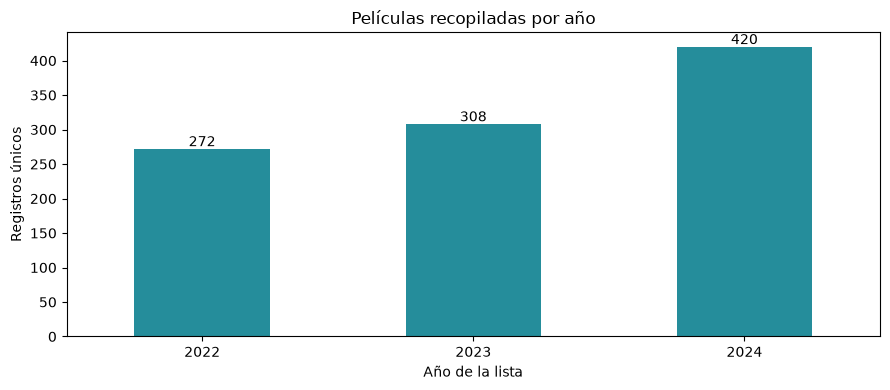

https://en.wikipedia.org/wiki/List_of_American_films_of_2024 → 420 candidatas
https://en.wikipedia.org/wiki/List_of_American_films_of_2023 → 308 candidatas
https://en.wikipedia.org/wiki/List_of_American_films_of_2022 → 291 candidatas


In [4]:
counts = frame.groupby('anio').size()
ax = counts.plot.bar(color='#258d9b', figsize=(9, 4), rot=0)
ax.set(title='Películas recopiladas por año', xlabel='Año de la lista', ylabel='Registros únicos')
for i, value in enumerate(counts): ax.text(i, value + 4, str(value), ha='center')
plt.tight_layout(); plt.show()
for page in record['paginas']: print(page['url'], '→', page['candidatas'], 'candidatas')

## 3. Repetir el rastreo

Desde la raíz: `python ejecutar.py peliculas --salida resultados_nuevos --maximo 1000`. Se consulta robots.txt, se espacia cada solicitud al menos 1.1 segundos y se rechazan archivos de destino existentes. La muestra está limitada a estrenos estadounidenses de las listas elegidas y no representa todo el cine. Los datos derivados de Wikipedia se distribuyen bajo CC BY-SA 4.0, con atribución por las columnas URL y lista de origen.